# Malayalam Named Entity Recognition — 04. Inference & Interactive Demo
Runs the final **IndicBERTv2 + CRF** model on raw Malayalam text and shows the deployment layer:
1. `MalayalamNERPredictor`: word splitting, subword alignment, CRF decoding and grouping into entity spans
2. A rule-based (regex) overlay that adds **DATE** and **CARDINAL** tags on top of PER/ORG/LOC
3. displaCy-style entity highlighting
4. Batch processing of a news document
5. A **Gradio** web app and a **FastAPI** REST endpoint

## 0. Environment Setup
Works both **locally** (run from the project's `submission codes/` folder, which sits next to `dataset/` and `results/`) and on **Google Colab** (Runtime → Change runtime type → GPU).

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip -q install "datasets<4" seqeval pytorch-crf gradio fastapi

# Project root = folder that contains dataset/ and results/
PROJECT_DIR = os.path.abspath("..") if os.path.isdir(os.path.join("..", "dataset")) else os.path.abspath(".")
print("Running in Colab:", IN_COLAB)
print("Project directory:", PROJECT_DIR)

Running in Colab: False
Project directory: E:\Downloads\SEM 7\NLP\Project


In [2]:
import torch
from transformers.utils import logging as hf_logging
from huggingface_hub.utils import disable_progress_bars, logging as hub_logging
hf_logging.set_verbosity_error(); hf_logging.disable_progress_bar()
hub_logging.set_verbosity_error(); disable_progress_bars()

# ---------------- Paths ----------------
DATA_DIR = os.path.join(PROJECT_DIR, "dataset")
TRAIN_CSV = os.path.join(DATA_DIR, "train.csv")
VAL_CSV = os.path.join(DATA_DIR, "validation.csv")
TEST_CSV = os.path.join(DATA_DIR, "test.csv")
MODEL_SAVE_DIR = os.path.join(PROJECT_DIR, "results", "malayalam_ner_model")          # IndicBERTv2 + Linear head
CRF_MODEL_SAVE_DIR = os.path.join(PROJECT_DIR, "results", "malayalam_ner_crf_model")  # IndicBERTv2 + CRF head

# ---------------- Hardware ----------------
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_FP16 = torch.cuda.is_available()

# ---------------- Model & labels (IOB2) ----------------
MODEL_NAME = "ai4bharat/IndicBERTv2-MLM-only"
ID2LABEL = {0: "O", 1: "B-PER", 2: "I-PER", 3: "B-ORG", 4: "I-ORG", 5: "B-LOC", 6: "I-LOC"}
LABEL2ID = {v: k for k, v in ID2LABEL.items()}
NUM_LABELS = len(ID2LABEL)
ENTITY_COLORS = {"PER": "#3B82F6", "ORG": "#10B981", "LOC": "#F59E0B",
                 "MISC": "#8B5CF6", "DATE": "#EC4899", "CARDINAL": "#06B6D4"}

# ---------------- Hyperparameters (used for the final models) ----------------
MAX_LENGTH = 128
BATCH_SIZE = 32 if torch.cuda.is_available() else 8
LEARNING_RATE = 3e-5
WEIGHT_DECAY = 0.01
EPOCHS = 3
SEED = 42
MAX_TRAIN_SAMPLES = 50000

print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU")
print("torch", torch.__version__)

Device: cuda | NVIDIA GeForce RTX 3050 6GB Laptop GPU
torch 2.6.0+cu124


**Dataset.** If `dataset/*.csv` is not present (e.g. on Colab), the Malayalam split of [Naamapadam](https://huggingface.co/datasets/ai4bharat/naamapadam) is downloaded from HuggingFace and exported to the same CSV format.

In [3]:
def ensure_dataset():
    if all(os.path.exists(p) for p in (TRAIN_CSV, VAL_CSV, TEST_CSV)):
        print("Dataset found in", DATA_DIR)
        return
    from datasets import load_dataset
    ds = load_dataset("ai4bharat/naamapadam", "ml", trust_remote_code=True)
    os.makedirs(DATA_DIR, exist_ok=True)
    for split, path in [("train", TRAIN_CSV), ("validation", VAL_CSV), ("test", TEST_CSV)]:
        df = ds[split].to_pandas()[["tokens", "ner_tags"]]
        df["tokens"] = df["tokens"].map(lambda x: str(list(x)))
        df["ner_tags"] = df["ner_tags"].map(lambda x: str([int(t) for t in x]))
        df.to_csv(path, index=False)
    print("Dataset downloaded and saved to", DATA_DIR)

ensure_dataset()

Dataset found in E:\Downloads\SEM 7\NLP\Project\dataset


**Checkpoints.** The fine-tuned weights (~1.1 GB each) are too large to submit. Locally they are read from `results/malayalam_ner_model` and `results/malayalam_ner_crf_model`. On Colab, upload them to Google Drive and point `MODEL_SAVE_DIR` / `CRF_MODEL_SAVE_DIR` at them, or train them with `02_Model_Training.ipynb` (`DEMO_MODE = False`).

In [4]:
import torch.nn as nn
from transformers import AutoModelForTokenClassification, AutoConfig, AutoModel, AutoTokenizer
from torchcrf import CRF


class MalayalamBERTCRF(nn.Module):
    """Transformer sequence encoder topped with a Conditional Random Field (CRF) layer."""
    def __init__(self, model_name=MODEL_NAME, num_labels=NUM_LABELS):
        super().__init__()
        self.num_labels = num_labels
        self.config = AutoConfig.from_pretrained(model_name)
        self.bert = AutoModel.from_pretrained(model_name, config=self.config)
        self.dropout = nn.Dropout(self.config.hidden_dropout_prob)
        self.classifier = nn.Linear(self.config.hidden_size, num_labels)
        self.crf = CRF(num_labels, batch_first=True)

    def forward(self, input_ids, attention_mask, labels=None):
        outputs = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        sequence_output = self.dropout(outputs[0])
        emissions = self.classifier(sequence_output)

        if labels is not None:
            # Valid positions = first subword of every word; [CLS] forced True for pytorch-crf
            mask = (labels != -100)
            mask[:, 0] = True
            clean_labels = labels.clone()
            clean_labels[clean_labels == -100] = 0
            loss = -self.crf(emissions, clean_labels, mask=mask, reduction='mean')
            return type('CRFOutput', (object,), {"loss": loss, "logits": emissions})()
        else:
            mask = (attention_mask == 1)
            preds = self.crf.decode(emissions, mask=mask)
            return type('CRFOutput', (object,), {"logits": emissions, "predictions": preds})()

    def save_pretrained(self, save_dir):
        os.makedirs(save_dir, exist_ok=True)
        torch.save(self.state_dict(), os.path.join(save_dir, "pytorch_model.bin"))
        self.config.save_pretrained(save_dir)

    def load_pretrained(self, save_dir):
        self.load_state_dict(torch.load(os.path.join(save_dir, "pytorch_model.bin"), map_location=DEVICE))


def build_ner_model(model_name=MODEL_NAME, num_labels=NUM_LABELS, use_crf=True):
    """Initializes standard Transformer token classifier or CRF-augmented model."""
    if use_crf:
        print("Configuring Model: IndicBERTv2 + Conditional Random Field (CRF) Head")
        return MalayalamBERTCRF(model_name=model_name, num_labels=num_labels)
    print("Configuring Model: IndicBERTv2 + Linear Token Classification Head")
    model_config = AutoConfig.from_pretrained(model_name, num_labels=num_labels,
                                              id2label=ID2LABEL, label2id=LABEL2ID)
    return AutoModelForTokenClassification.from_pretrained(model_name, config=model_config)

## 1. Predictor

In [5]:
import re
import numpy as np

USE_CRF = True


class MalayalamNERPredictor:
    def __init__(self, model_path=None):
        if USE_CRF:
            model_path = model_path or CRF_MODEL_SAVE_DIR
            print(f"Loading CRF Predictor checkpoint: {model_path}")
            self.tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
            self.model = MalayalamBERTCRF(model_name=MODEL_NAME)
            self.model.load_pretrained(model_path)
        else:
            model_path = model_path or MODEL_SAVE_DIR
            print(f"Loading Linear Predictor checkpoint: {model_path}")
            self.tokenizer = AutoTokenizer.from_pretrained(model_path)
            self.model = AutoModelForTokenClassification.from_pretrained(model_path)
        self.model.to(DEVICE)
        self.model.eval()

    def predict(self, text):
        """Predicts named entities for raw Malayalam input text."""
        # Split Malayalam text into words without breaking Indic glyph clusters
        words = re.findall(r'[^\s.,!?\(\)\x22\x27\-]+|[.,!?\(\)\x22\x27\-]', text)
        if not words:
            return [], []

        encoding = self.tokenizer(words, is_split_into_words=True, truncation=True,
                                  max_length=MAX_LENGTH, return_tensors="pt")
        input_ids = encoding["input_ids"].to(DEVICE)
        attention_mask = encoding["attention_mask"].to(DEVICE)
        word_ids = encoding.word_ids(batch_index=0)

        word_tag_map = []
        previous_word_idx = None
        with torch.no_grad():
            outputs = self.model(input_ids=input_ids, attention_mask=attention_mask)
            probs = torch.softmax(outputs.logits, dim=-1).squeeze(0).cpu().numpy()
            if USE_CRF:
                tag_ids = outputs.predictions[0]
            else:
                tag_ids = probs.argmax(-1).tolist()
            for idx, word_idx in enumerate(word_ids):
                if word_idx is not None and word_idx != previous_word_idx:
                    if word_idx < len(words) and idx < len(tag_ids):
                        word_tag_map.append({"word": words[word_idx],
                                             "tag": ID2LABEL.get(int(tag_ids[idx]), "O"),
                                             "confidence": round(float(np.max(probs[idx])), 4)})
                    previous_word_idx = word_idx

        # --- Hybrid Rule-Based (Regex) Overlay: DATE and CARDINAL ---
        months_pattern = re.compile(
            r"^(ജനുവരി|ഫെബ്രുവരി|മാർച്ച്|ഏപ്രിൽ|മേയ്|ജൂൺ|ജൂലൈ|ഓഗസ്റ്റ്|സെപ്റ്റംബർ|ഒക്ടോബർ|നവംബർ|ഡിസംബർ)$")
        cardinal_pattern = re.compile(
            r"^(?=.*[\d\u0D66-\u0D6F])[\d%\.\+\-,\u0D66-\u0D6F]+(?:ശതമാനം|രൂപ|ജിബി|ലക്ഷം|കോടി|വർഷം|മാസം|ദിവസം)?$")

        for i, item in enumerate(word_tag_map):
            word = item["word"]
            if item["tag"] != "O":  # keep neural PER/ORG/LOC predictions
                continue
            if months_pattern.match(word):
                item["tag"], item["confidence"] = "B-DATE", 1.0
                continue
            if cardinal_pattern.match(word) or any(c.isdigit() for c in word):
                is_date = any(0 <= i + o < len(word_tag_map) and months_pattern.match(word_tag_map[i + o]["word"])
                              for o in [-2, -1, 1, 2])
                if is_date:
                    item["tag"] = "I-DATE" if i > 0 and word_tag_map[i - 1]["tag"] in ["B-DATE", "I-DATE"] else "B-DATE"
                else:
                    item["tag"] = "B-CARDINAL"

        # Force-merge formatted dates (DD-MM-YYYY, YYYY/MM/DD ...)
        i = 0
        while i < len(word_tag_map) - 4:
            w = [word_tag_map[i + k]["word"] for k in range(5)]
            if w[0].isdigit() and w[1] in ["-", "/"] and w[2].isdigit() and w[3] in ["-", "/"] and w[4].isdigit():
                for k in range(5):
                    word_tag_map[i + k]["tag"] = "B-DATE" if k == 0 else "I-DATE"
                    word_tag_map[i + k]["confidence"] = 1.0
                i += 5
                continue
            i += 1

        # Group into entity spans
        entities, current = [], None
        for item in word_tag_map:
            word, tag, conf = item["word"], item["tag"], item["confidence"]
            if tag.startswith("B-"):
                if current:
                    entities.append(current)
                current = {"text": word, "type": tag.split("-")[1], "confidence": conf, "words": [word]}
            elif tag.startswith("I-") and current and tag.split("-")[1] == current["type"]:
                current["words"].append(word)
                current["text"] += " " + word
                current["confidence"] = round((current["confidence"] + conf) / 2, 4)
            else:
                if current:
                    entities.append(current)
                current = None
        if current:
            entities.append(current)

        for ent in entities:
            if ent["type"] == "DATE":
                ent["text"] = ent["text"].replace(" - ", "-").replace(" / ", "/")
        return word_tag_map, entities

In [6]:
predictor = MalayalamNERPredictor()

Loading CRF Predictor checkpoint: E:\Downloads\SEM 7\NLP\Project\results\malayalam_ner_crf_model


## 2. Single-sentence Prediction

In [7]:
import pandas as pd
sample_text = "കോൺഗ്രസ് സംസ്ഥാന അധ്യക്ഷൻ ജി പരമേശ്വര ഉപമുഖ്യമന്ത്രിയാകും ."
word_map, entities = predictor.predict(sample_text)
print("Input:", sample_text, "\n")
for ent in entities:
    print(f" - [{ent['type']}] {ent['text']} (confidence {ent['confidence'] * 100:.1f}%)")
pd.DataFrame(word_map)

Input: കോൺഗ്രസ് സംസ്ഥാന അധ്യക്ഷൻ ജി പരമേശ്വര ഉപമുഖ്യമന്ത്രിയാകും . 

 - [ORG] കോൺഗ്രസ് (confidence 99.0%)
 - [PER] ജി പരമേശ്വര (confidence 97.0%)


,word,tag,confidence
0,കോൺഗ്രസ്,B-ORG,0.9904
1,സംസ്ഥാന,O,0.9416
2,അധ്യക്ഷൻ,O,0.9893
3,ജി,B-PER,0.9667
4,പരമേശ്വര,I-PER,0.9739
5,ഉപമുഖ്യമന്ത്രിയാകും,O,0.9009
6,.,O,0.9997


## 3. displaCy-style Visualisation

In [8]:
from IPython.display import HTML, display
import html as _html

def render(text):
    word_map, _ = predictor.predict(text)
    out, i = [], 0
    while i < len(word_map):
        tag = word_map[i]["tag"]
        if tag == "O":
            out.append(_html.escape(word_map[i]["word"])); i += 1; continue
        typ, span = tag[2:], [word_map[i]["word"]]; i += 1
        while i < len(word_map) and word_map[i]["tag"] == f"I-{typ}":
            span.append(word_map[i]["word"]); i += 1
        c = ENTITY_COLORS.get(typ, "#999")
        out.append(f'<mark style="background:{c}22;border:1px solid {c};padding:2px 6px;border-radius:6px;line-height:2.2">'
                   f'{_html.escape(" ".join(span))} <b style="font-size:.7em;color:{c}">{typ}</b></mark>')
    return " ".join(out)

examples = [
    "കോൺഗ്രസ് സംസ്ഥാന അധ്യക്ഷൻ ജി പരമേശ്വര ഉപമുഖ്യമന്ത്രിയാകും .",
    "തിരുവനന്തപുരത്ത് നടന്ന ചടങ്ങിൽ കേരള മുഖ്യമന്ത്രി പിണറായി വിജയൻ സംസാരിച്ചു .",
    "ഇന്ത്യൻ ബഹിരാകാശ ഗവേഷണ സംഘടന ( ഐഎസ്ആർഒ ) ശ്രീഹരിക്കോട്ടയിൽ പുതിയ ഉപഗ്രഹം വിക്ഷേപിച്ചു .",
    "കൊച്ചി നഗരത്തിൽ കൊച്ചി മെട്രോ രണ്ടാം ഘട്ട നിർമ്മാണം ആരംഭിച്ചു .",
    "2023 ഓഗസ്റ്റ് 15 ന് 500 കോടി രൂപയുടെ പദ്ധതി പ്രഖ്യാപിച്ചു . 12-04-2023",
]
display(HTML("<div style='font-size:16px'>" + "<hr>".join(f"<p>{render(t)}</p>" for t in examples) + "</div>"))

## 4. Batch Processing of a News Document

In [9]:
news_path = os.path.join(PROJECT_DIR, "sample_malayalam_news.txt")
if not os.path.exists(news_path):  # fallback when the project files are not available (e.g. Colab)
    news_path = "sample_malayalam_news.txt"
    with open(news_path, "w", encoding="utf-8") as f:
        f.write("\n".join(examples))

lines = [l.strip() for l in open(news_path, encoding="utf-8") if l.strip()]
counts = {}
for line in lines:
    for ent in predictor.predict(line)[1]:
        counts[(ent["text"], ent["type"])] = counts.get((ent["text"], ent["type"]), 0) + 1
print(f"Processed {len(lines)} lines, found {len(counts)} unique entities.")
batch_df = pd.DataFrame([{"Entity Text": t, "Entity Class": c, "Occurrences": n}
                         for (t, c), n in sorted(counts.items(), key=lambda x: -x[1])])
batch_df.head(15)

Processed 18 lines, found 31 unique entities.


,Entity Text,Entity Class,Occurrences
0,തിരുവനന്തപുരത്ത്,LOC,3
1,കൊച്ചിയിൽ,LOC,3
2,പിണറായി വിജയൻ,PER,1
3,കൊച്ചി,LOC,1
4,മെട്രോ,ORG,1
5,ഇന്ത്യൻ ബഹിരാകാശ ഗവേഷണ സംഘടന,ORG,1
6,ഐഎസ്ആർഒ,ORG,1
7,ശ്രീഹരിക്കോട്ടയിൽ,LOC,1
8,കൊച്ചി മെട്രോ റെയിൽ ലിമിറ്റഡ്,ORG,1
9,കേരളത്തിൽ,LOC,1


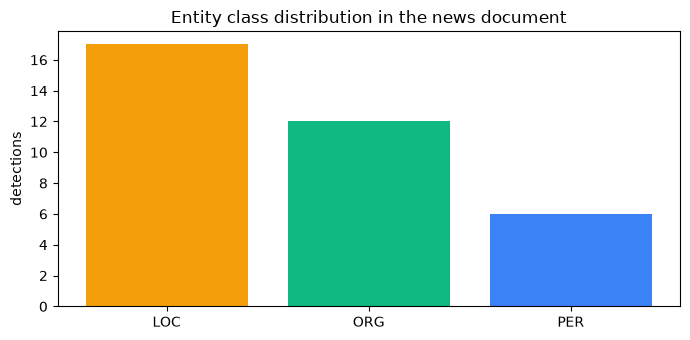

In [10]:
import matplotlib.pyplot as plt
tot = batch_df.groupby("Entity Class")["Occurrences"].sum().sort_values(ascending=False)
plt.figure(figsize=(7, 3.5))
plt.bar(tot.index, tot.values, color=[ENTITY_COLORS.get(k, "#999") for k in tot.index])
plt.title("Entity class distribution in the news document"); plt.ylabel("detections")
plt.tight_layout(); plt.show()

## 5. REST API (FastAPI)
The same predictor is exposed as a `POST /predict` endpoint. Here it is exercised in-process with FastAPI's test client.

In [11]:
from fastapi import FastAPI, HTTPException
from fastapi.testclient import TestClient
from pydantic import BaseModel

api = FastAPI(title="Malayalam Named Entity Recognition (NER) API", version="1.0.0")

class TextRequest(BaseModel):
    text: str

@api.post("/predict")
def predict_ner(payload: TextRequest):
    if not payload.text or not payload.text.strip():
        raise HTTPException(status_code=400, detail="Input text cannot be empty.")
    word_map, entities = predictor.predict(payload.text)
    return {"text": payload.text, "entities": entities, "word_level_tags": word_map}

client = TestClient(api)
resp = client.post("/predict", json={"text": examples[1]})
print("Status:", resp.status_code)
for e in resp.json()["entities"]:
    print(e["type"], "->", e["text"], e["confidence"])
# To serve it: uvicorn.run(api, host="127.0.0.1", port=8000)

Status: 200
LOC -> തിരുവനന്തപുരത്ത് 0.5711
LOC -> കേരള 0.9007
PER -> പിണറായി വിജയൻ 0.9895


## 6. Gradio Web App
Set `LAUNCH_APP = True` to start the interactive visualiser (on Colab a public share link is created).

In [12]:
import gradio as gr
import urllib.parse

ALL = ["PER", "ORG", "LOC", "DATE", "CARDINAL"]

def process_malayalam_ner(text, visible_entities=None):
    visible_entities = visible_entities or ALL
    if not text or not text.strip():
        return [], pd.DataFrame(columns=["Entity Text", "Entity Class", "Confidence Score", "Quick Search"])
    word_map, entities = predictor.predict(text)
    highlighted = []
    for idx, item in enumerate(word_map):
        word, tag = item["word"], item["tag"]
        nxt = word_map[idx + 1]["word"] if idx < len(word_map) - 1 else ""
        space = "" if word in ["-", "/", "(", "["] or nxt in ["-", "/", ".", ",", "!", "?", ")", "]"] else " "
        typ = tag.split("-")[1] if tag != "O" else None
        highlighted.append((word + space, typ if typ in visible_entities else None))
    rows = []
    for ent in entities:
        if ent["type"] not in visible_entities:
            continue
        q = urllib.parse.quote(ent["text"])
        link = f"[Wikipedia](https://ml.wikipedia.org/wiki/Special:Search?search={q})" if ent["type"] in ["PER", "LOC", "ORG"] else "—"
        rows.append({"Entity Text": ent["text"], "Entity Class": ent["type"],
                     "Confidence Score": f"{ent['confidence'] * 100:.1f}%", "Quick Search": link})
    return highlighted, pd.DataFrame(rows, columns=["Entity Text", "Entity Class", "Confidence Score", "Quick Search"])

with gr.Blocks(title="displaCy Named Entity Visualizer") as demo:
    gr.Markdown("# displaCy Named Entity Visualizer\nInteractive Named Entity Recognition for Malayalam (fine-tuned IndicBERTv2 + CRF)")
    with gr.Row():
        with gr.Column(scale=3):
            input_text = gr.Textbox(lines=6, label="Text to analyze", value=examples[1])
            btn = gr.Button("Visualise Entities", variant="primary")
            gr.Examples(examples=[[e] for e in examples], inputs=input_text)
        with gr.Column(scale=2):
            visible = gr.CheckboxGroup(choices=ALL, value=ALL, label="Entity labels")
    out_hl = gr.HighlightedText(label="Visualised Entities", color_map=ENTITY_COLORS, combine_adjacent=True)
    out_tb = gr.Dataframe(datatype=["str", "str", "str", "markdown"], interactive=False, wrap=True)
    btn.click(process_malayalam_ner, [input_text, visible], [out_hl, out_tb])
    visible.change(process_malayalam_ner, [input_text, visible], [out_hl, out_tb])

hl, tb = process_malayalam_ner(examples[2])
print("Gradio handler output (non-O spans):", [h for h in hl if h[1]])
tb

Gradio handler output (non-O spans): [('ഇന്ത്യൻ ', 'ORG'), ('ബഹിരാകാശ ', 'ORG'), ('ഗവേഷണ ', 'ORG'), ('സംഘടന ', 'ORG'), ('ഐഎസ്ആർഒ', 'ORG'), ('ശ്രീഹരിക്കോട്ടയിൽ ', 'LOC')]


,Entity Text,Entity Class,Confidence Score,Quick Search
0,ഇന്ത്യൻ ബഹിരാകാശ ഗവേഷണ സംഘടന,ORG,94.7%,[Wikipedia](https://ml.wikipedia.org/wiki/Spec...
1,ഐഎസ്ആർഒ,ORG,97.6%,[Wikipedia](https://ml.wikipedia.org/wiki/Spec...
2,ശ്രീഹരിക്കോട്ടയിൽ,LOC,74.5%,[Wikipedia](https://ml.wikipedia.org/wiki/Spec...


In [13]:
LAUNCH_APP = False
if LAUNCH_APP:
    demo.launch(share=IN_COLAB)

## Summary
- The CRF model correctly recognises persons, organisations and locations in unseen news text, including multi-word and agglutinated forms.
- The regex overlay adds DATE and CARDINAL entities, which Naamapadam does not annotate.
- The predictor is exposed through both a Gradio UI and a FastAPI endpoint.